In [1]:
# graphing mass_loss_tao.py
import sys
sys.path.insert(0, './Models')
import numpy as np
import matplotlib.pyplot as plt
#import module_mass_loss as mml
import xpml

from astropy.table import Table

In [82]:
#physical constants
Ggrav = 6.67e-11 #gravitational constant m^3/kg/sec^2
Rmol = 8.314 #ideal gas constant (J/mol/K)

#astronomical constants
M_e = 5.97237e24 #Earth mass (kg)
R_e = 6.371e6 #Earth radius (m)
M_sun = 1.9885e30 #Sun mass (kg)
R_sun = 6.9551e10 #Sun radius (m)
L_sun = 3.828e26 #Total luminosity of the Sun (Watts = Joules/sec)
T_sun = 5778. #Temperature of the Sun (K)
au = 1.496e11 #Astronomical Unit (m)
Gyr = 3.153e16 #Seconds in 1 Gyr

In [131]:
planet = 5000
fname = f'./evolution-data/gp-evo/{planet}_xp_070925/planet_1-{planet}_evolution_data.csv'
time_saved,mp_saved,rp_saved,wmf_saved,mdot_saved = np.loadtxt(fname,unpack=True)


# swe_fname = f'./../../TOI_836b_swe_mass_loss_data.csv'
# s_time_saved,s_mp_saved,s_wmf_saved,s_rp_saved = \
#     np.loadtxt(swe_fname,skiprows=1,usecols=(0,1,2,3), unpack=True) #,err_saved
# iop_fname = f'./../../TOI_836b_iop_mass_loss_data.csv'
# i_time_saved,i_mp_saved,i_wmf_saved,i_rp_saved = \
#     np.loadtxt(iop_fname,skiprows=1,usecols=(0,1,2,3), unpack=True) #,err_saved

In [77]:
loadin_path = './evolution-data/gp-evo/100_xp/100_xp_gp_data.csv'
planetnum, mp_gp, rp_gp, mcore_gp, rsurf_gp, teq_gp, wmf_gp, grav_gp, H_gp, lambda_gp, sep_gp, period_gp, startype_gp, mstar_gp, lstar_gp, mdot_gp = np.loadtxt(loadin_path, unpack=True)


In [78]:
print(startype_gp)

[1. 1. 1. 0. 0. 0. 0. 0. 1. 1. 0. 1. 0. 1. 0. 1. 1. 1. 0. 0. 1. 0. 1. 0.
 1. 0. 1. 1. 1. 1. 1. 1. 0. 0. 1. 0. 1. 1. 0. 0. 1. 1. 0. 0. 0. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 0. 1. 1. 1. 1. 0. 1.
 1. 0. 0. 1. 1. 1. 1. 0. 1. 0. 0. 1. 1. 1. 1. 1. 1. 1. 0. 0. 1. 0. 1. 1.
 1. 1. 1. 1.]


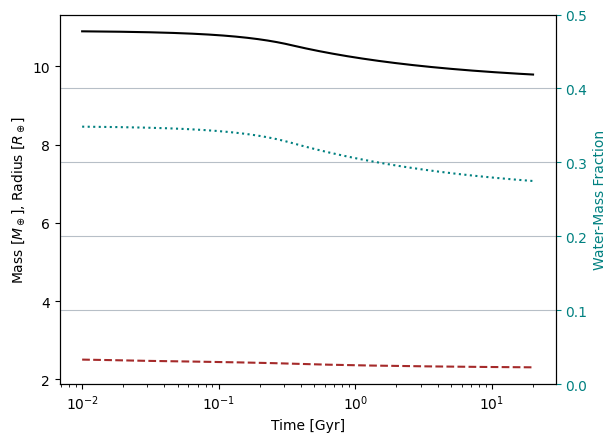

In [134]:
fig, ax = plt.subplots()

ax.plot(time_saved, mp_saved, color='black', label='Mass')
ax.plot(time_saved, rp_saved, color='brown', linestyle='--',label='Radius')
ax.set(xlabel='Time [Gyr]',xscale='log',ylabel=r'Mass [$M_\oplus$], Radius [$R_\oplus$]')

ax2 = ax.twinx()
ax2.plot(time_saved, wmf_saved, color='teal', linestyle=':',label='WMF')
ax2.set_ylabel('Water-Mass Fraction',color='teal')
ax2.tick_params(axis='y',colors='teal')
ax2.grid(color='slategrey',alpha=0.5)
ax2.set(ylim=[0,.5])
# plt.legend()
plt.savefig('stacked.png',bbox_inches='tight',dpi=600)
plt.show()

In [79]:
# Display planet info (Earth units)

print('PLANET POPULATION INFORMATION')
gp_table = Table()
gp_table["Number"] = planetnum
gp_table["Mass (M🜨)"] = mp_gp/M_e
gp_table["Radius (R🜨)"] = rp_gp/R_e
gp_table["Teq (K)"] = teq_gp
gp_table["WMF"] = wmf_gp
gp_table["Gravity (m/s^2)"] = grav_gp
gp_table["Scale Height (km)"] = H_gp/1000
gp_table["Lambda"] = lambda_gp
gp_table["Period (days)"] = period_gp
gp_table["Sep (au)"] = sep_gp/au
gp_table["Star Type"] = startype_gp
gp_table["Lstar (L☉)"] = lstar_gp/L_sun
gp_table["Mstar (M☉)"] = mstar_gp/M_sun
gp_table["initial mdot"] = mdot_gp

gp_table["Mass (M🜨)"].format = "{:.3f}"
gp_table["Radius (R🜨)"].format = "{:.3f}"
gp_table["Teq (K)"].format = "{:.3f}"
gp_table["WMF"].format = "{:.3f}"
gp_table["Gravity (m/s^2)"].format = "{:.3f}"
gp_table["Scale Height (km)"].format = "{:.1f}"
gp_table["Lambda"].format = "{:.3f}"
gp_table["Period (days)"].format = "{:.1f}"
gp_table["Sep (au)"].format = "{:.3f}"
gp_table["Lstar (L☉)"].format = "{:.3f}"
gp_table["Mstar (M☉)"].format = "{:.3f}"
gp_table["initial mdot"].format = "{:.3e}"
print(gp_table)

# Idk why it isn't working

PLANET POPULATION INFORMATION
Number Mass (M🜨) Radius (R🜨) Teq (K)  ... Lstar (L☉) Mstar (M☉) initial mdot
------ --------- ----------- -------- ... ---------- ---------- ------------
   1.0     9.603       2.406 1063.547 ...      0.809      0.948    1.272e+08
   2.0     5.295       2.378  510.094 ...      0.155      0.628    2.405e+07
   3.0     9.611       2.045  960.705 ...      0.322      0.753    4.899e+07
   4.0     4.151       2.316  615.560 ...      0.008      0.230    1.440e+08
   5.0     4.969       2.034 1197.598 ...      0.012      0.274    2.317e+09
   6.0     8.520       2.353  754.136 ...      0.022      0.363    6.704e+07
   7.0     6.234       1.939  854.125 ...      0.006      0.199    1.602e+08
   8.0     9.301       2.215 1193.020 ...      0.013      0.285    6.559e+08
   9.0    11.053       2.755  788.286 ...      1.112      1.027    4.537e+07
  10.0     3.494       1.914  586.955 ...      0.094      0.554    4.457e+07
   ...       ...         ...      ... ...     

In [70]:
print(len(time_saved))

19983


In [83]:
mdot = xpml.solve_mdot(mp_gp[0],rp_gp[0],mstar_gp[0],sep_gp[0],1e-2*Gyr,lstar_gp[0])

print(mp_gp[0],rp_gp[0],mstar_gp[0],sep_gp[0],1e-2*Gyr,lstar_gp[0])
print(mp_saved[0],rp_saved[0],mstar_gp[0],sep_gp[0],time_saved[0],lstar_gp[0])

print(f'{mdot:.5e}')

print(f'{mdot_saved[0]:.5e}')

5.73538e+25 15326700.0 1.88543e+30 9215520000.0 315300000000000.0 3.09704e+26
5.73538e+25 15326700.0 1.88543e+30 9215520000.0 315300000000000.0 3.09704e+26
1.27193e+08
1.62197e+06


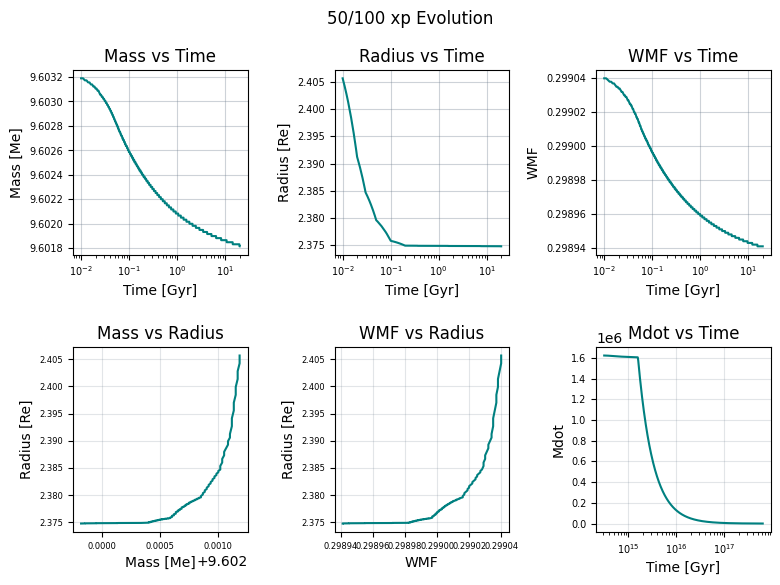

In [87]:
# plt.style.use('dark_background')
color = 'teal'

figure, axes = plt.subplots(2,3)  # 1,3
figure.suptitle(f'50/100 xp Evolution')
figure.set_figheight(6)
figure.set_figwidth(9)
plt.subplots_adjust(wspace=0.5,hspace=.5)
# plt.rc('figure', labelsize=8)
# plt.rc('axes', labelsize=8)
#mp+t
axes[0,0].plot(time_saved/Gyr, mp_saved/M_e, color=color)
axes[0,0].tick_params(axis='both', which='major', labelsize=7)
axes[0,0].grid(visible=True, color='slategrey', alpha=0.35, which='major', axis='both')
axes[0,0].set_xscale('log')
#axes[0].tick_params(axis='both', labelrotation=25)
axes[0,0].set_xlabel('Time [Gyr]')
axes[0,0].set_ylabel('Mass [Me]')
axes[0,0].set_title('Mass vs Time')

#rp+t
axes[0,1].plot(time_saved[:-1]/Gyr, rp_saved[:-1]/R_e, color=color)
axes[0,1].tick_params(axis='both', which='major', labelsize=7)
axes[0,1].grid(visible=True, color='slategrey', alpha=0.35, which='major', axis='both')
axes[0,1].set_xscale('log')
axes[0,1].set_xlabel('Time [Gyr]')
axes[0,1].set_ylabel('Radius [Re]')
axes[0,1].set_title('Radius vs Time')

#wmf+t
axes[0,2].plot(time_saved/Gyr, wmf_saved, color=color)
axes[0,2].tick_params(axis='both', which='major', labelsize=7)
axes[0,2].grid(visible=True, color='slategrey', alpha=0.35, which='major', axis='both')
axes[0,2].set_xscale('log')
axes[0,2].set_xlabel('Time [Gyr]')
axes[0,2].set_ylabel('WMF')
axes[0,2].set_title('WMF vs Time')

#rp + mp
axes[1,0].plot(mp_saved/M_e, rp_saved/R_e, color=color)
axes[1,0].tick_params(axis='both', which='major', labelsize=6)
axes[1,0].grid(visible=True, color='slategrey', alpha=0.2, which='major', axis='both')
axes[1,0].set_xlabel('Mass [Me]')
axes[1,0].set_ylabel('Radius [Re]')
axes[1,0].set_title('Mass vs Radius')

#wmf + rp
axes[1,1].plot(wmf_saved, rp_saved/R_e, color=color)
axes[1,1].tick_params(axis='both', which='major', labelsize=6)
axes[1,1].grid(visible=True, color='slategrey', alpha=0.2, which='major', axis='both')
axes[1,1].set_xlabel('WMF')
axes[1,1].set_ylabel('Radius [Re]')
axes[1,1].set_title('WMF vs Radius')

#mdot+time
M_moon = 7.3476e22 #kg
axes[1,2].plot(time_saved, mdot_saved, color=color)
axes[1,2].tick_params(axis='both', which='major', labelsize=7)
axes[1,2].grid(visible=True, color='slategrey', alpha=0.2, which='major', axis='both')
axes[1,2].set_xscale('log')
axes[1,2].set_xlabel('Time [Gyr]')
axes[1,2].set_ylabel('Mdot')
axes[1,2].set_title('Mdot vs Time')

figure.set_label(f'{planet}')
# figure.subplots_adjust(wspace=0.5, hspace=0.5, top=0.65)
# plt.savefig(f'./plots/individual_planet_plots{planet}_6_graphsx.png', dpi=600, bbox_inches='tight',pad_inches=0.4)
plt.show()

### Individual plots

In [ ]:
plt.plot(time_saved/Gyr, mp_saved/M_e, color=color)
plt.title(f'{planet} Mass over Time')
plt.xlabel('Time [Gyr]')
plt.ylabel('Planet Mass [Me]')
plt.xscale('log')
plt.grid(True)
# plt.savefig(f'{planet}_mp_t_plot.pdf')
plt.show()

In [ ]:
plt.plot(time_saved/Gyr, wmf_saved, color=color)
plt.title(f'{planet} WMF over Time')
plt.xlabel('Time [Gyr]')
plt.ylabel('Water-Mass Fraction [1]')
plt.xscale('log')
plt.grid(True)
# plt.savefig(f'{planet}_wmf_t_plot.pdf')
plt.show()

In [ ]:
plt.plot(mp_saved/M_e, rp_saved/R_e, color=color)
plt.title(f'{planet} Radius vs Mass')
plt.xlabel('Radius [Re]')
plt.ylabel('Mass [Me]')
plt.grid(True)
# plt.savefig(f'{planet}_rp_mp_plot.pdf')
plt.show()

In [ ]:
plt.plot(time_saved/Gyr, rp_saved/R_e, color=color)
plt.title(f'{planet} Radius over Time')
plt.xlabel('Time [Gyr]')
plt.ylabel('Planet Radius [Re]')
plt.xscale('log')
plt.grid(True)
# plt.savefig(f'{planet}_{planet}_rp_t_plot.pdf')
plt.show()

In [ ]:
plt.plot(wmf_saved, rp_saved/R_e, color=color)
plt.title(f'{planet} WMF vs Radius')
plt.ylabel('Radius [Re]')
plt.xlabel('Water-Mass Fraction [1]')
plt.grid(True)
# plt.savefig(f'{planet}_wmf_rp_plot.pdf')
plt.show()

In [ ]:
plt.plot(time_saved/Gyr, mp_saved/M_e, color=color)
plt.title(f'{planet} Mass over Time (Mdot)')
plt.xlabel('Time [Gyr]')
plt.ylabel('Mass [Me]')
plt.xscale('log')
plt.grid(True)
#plt.savefig(f'{planet}_mdot_plot.pdf')
plt.show()

In [ ]:
plt.plot(time_saved/Gyr, err_saved, color=color)
plt.title(f'{planet} Simulation Errors')
plt.xlabel('Time [Gyr]')
plt.ylabel('Error Code [1]')
plt.xscale('log')
plt.grid(True)
# plt.savefig(f'{planet}_errors_plot.pdf')
plt.show()